In [107]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [109]:
df=pd.read_csv('/content/drive/MyDrive/online-store-sales-project/Online-Store-Orders.csv')

In [110]:
df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [111]:
df.shape

(1200, 14)

In [112]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          1200 non-null   object 
 1   Date             1200 non-null   object 
 2   CustomerID       1200 non-null   object 
 3   Product          1200 non-null   object 
 4   Quantity         1200 non-null   int64  
 5   UnitPrice        1200 non-null   float64
 6   ShippingAddress  1200 non-null   object 
 7   PaymentMethod    1200 non-null   object 
 8   OrderStatus      1200 non-null   object 
 9   TrackingNumber   1200 non-null   object 
 10  ItemsInCart      1200 non-null   int64  
 11  CouponCode       891 non-null    object 
 12  ReferralSource   1200 non-null   object 
 13  TotalPrice       1200 non-null   float64
dtypes: float64(2), int64(2), object(10)
memory usage: 131.4+ KB


In [113]:
df.describe()

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,2.945833,356.412750,5.485000,1053.968300
std,1.407557,197.177146,2.281983,819.856558
min,1.000000,11.390000,1.000000,11.390000
25%,2.000000,186.062500,4.000000,410.520000
50%,3.000000,364.210000,5.000000,823.615000
75%,4.000000,521.570000,7.000000,1578.475000
max,5.000000,699.930000,10.000000,3456.400000


In [114]:
df.dtypes

,0
OrderID,object
Date,object
CustomerID,object
Product,object
Quantity,int64
UnitPrice,float64
ShippingAddress,object
PaymentMethod,object
OrderStatus,object
TrackingNumber,object


In [115]:
df.isnull().sum()

,0
OrderID,0
Date,0
CustomerID,0
Product,0
Quantity,0
UnitPrice,0
ShippingAddress,0
PaymentMethod,0
OrderStatus,0
TrackingNumber,0


In [116]:
df.columns

Index(['OrderID', 'Date', 'CustomerID', 'Product', 'Quantity', 'UnitPrice',
       'ShippingAddress', 'PaymentMethod', 'OrderStatus', 'TrackingNumber',
       'ItemsInCart', 'CouponCode', 'ReferralSource', 'TotalPrice'],
      dtype='object')

In [117]:
print("status:",df["OrderStatus"].unique())
print("\npaymentmethod: ",df["PaymentMethod"].unique())
print("\nShippingAddress",df["ShippingAddress"].unique())


status: ['Shipped' 'Cancelled' 'Returned' 'Delivered' 'Pending']

paymentmethod:  ['Debit Card' 'Online' 'Credit Card' 'Gift Card' 'Cash']

ShippingAddress ['928 Main St' '823 Main St' '512 Main St' '275 Main St' '668 Main St'
 '934 Main St' '986 Main St' '706 Main St' '904 Main St' '102 Main St'
 '333 Main St' '831 Main St' '179 Main St' '903 Main St' '980 Main St'
 '942 Main St' '914 Main St' '382 Main St' '891 Main St' '273 Main St'
 '587 Main St' '569 Main St' '633 Main St' '755 Main St' '956 Main St'
 '709 Main St' '296 Main St' '881 Main St' '568 Main St' '930 Main St'
 '895 Main St' '996 Main St' '830 Main St' '912 Main St' '926 Main St'
 '128 Main St' '465 Main St' '409 Main St' '549 Main St' '666 Main St'
 '267 Main St' '657 Main St' '871 Main St' '157 Main St' '223 Main St'
 '323 Main St' '464 Main St' '446 Main St' '434 Main St' '232 Main St'
 '623 Main St' '565 Main St' '566 Main St' '842 Main St' '202 Main St'
 '811 Main St' '634 Main St' '104 Main St' '691 Main St' '813 M

In [118]:
df.duplicated().sum()

np.int64(0)

In [119]:
print("Duplicate order =" ,df["OrderID"].duplicated().sum())
print("Duplicate customer= ",df["CustomerID"].duplicated().sum())

Duplicate order = 0
Duplicate customer=  11


Customer IDs can appear multiple times because a customer may place more than one order. Therefore, repeated Customer IDs do not necessarily indicate duplicate records.

In [120]:
df[df["Quantity"] <= 0]

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice


In [121]:
df[df["UnitPrice"] <= 0]

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice


In [122]:
df[df["TotalPrice"] <= 0]

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice


In [123]:
print("Date  range: ",df["Date"].min(), "to ", df["Date"].max())


Date  range:  2023-01-01 to  2025-06-30


In [124]:
print(df["OrderStatus"].value_counts(),"\n\n",
df["PaymentMethod"].value_counts(),"\n\n",
df["ReferralSource"].value_counts(),"\n\n",
df["Product"].value_counts())

OrderStatus
Cancelled    250
Returned     247
Pending      237
Shipped      235
Delivered    231
Name: count, dtype: int64 

 PaymentMethod
Online         258
Cash           246
Credit Card    234
Debit Card     232
Gift Card      230
Name: count, dtype: int64 

 ReferralSource
Instagram    259
Email        250
Google       241
Facebook     228
Referral     222
Name: count, dtype: int64 

 Product
Printer    181
Tablet     179
Chair      178
Laptop     173
Desk       170
Monitor    163
Phone      156
Name: count, dtype: int64


In [125]:
df["CalculatedTotal"] = df["Quantity"] * df["UnitPrice"]

In [126]:
df[df["CalculatedTotal"] != df["TotalPrice"]]

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice,CalculatedTotal
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40,2753.40
10,ORD200010,2023-12-29,C43443,Tablet,5,625.97,333 Main St,Credit Card,Returned,TRK98859248,9,WINTER15,Instagram,3129.85,3129.85
11,ORD200011,2024-02-17,C93861,Monitor,3,49.14,831 Main St,Online,Returned,TRK48234646,7,SAVE10,Email,147.42,147.42
32,ORD200032,2023-05-01,C12388,Tablet,5,536.72,830 Main St,Cash,Delivered,TRK99261395,10,NaN,Email,2683.60,2683.60
39,ORD200039,2025-02-27,C96664,Printer,3,256.46,666 Main St,Credit Card,Delivered,TRK85508960,4,SAVE10,Referral,769.38,769.38
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1166,ORD201166,2023-07-31,C95568,Chair,3,324.47,971 Main St,Cash,Delivered,TRK37075292,4,WINTER15,Email,973.41,973.41
1175,ORD201175,2024-09-10,C62512,Printer,3,91.74,368 Main St,Debit Card,Returned,TRK24139954,8,FREESHIP,Referral,275.22,275.22
1189,ORD201189,2024-08-17,C96136,Tablet,5,389.22,149 Main St,Cash,Cancelled,TRK60856682,7,NaN,Referral,1946.10,1946.10
1192,ORD201192,2024-02-28,C72007,Chair,3,432.85,999 Main St,Online,Pending,TRK16240916,4,NaN,Instagram,1298.55,1298.55


In [127]:
df["Difference"] = df["CalculatedTotal"] - df["TotalPrice"]

df["Difference"].describe()

,Difference
count,1.200000e+03
mean,-2.676378e-15
std,8.098100e-14
min,-4.547474e-13
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,4.547474e-13


In [128]:
df[~np.isclose(df["CalculatedTotal"], df["TotalPrice"])]

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice,CalculatedTotal,Difference


The calculated totals match the recorded TotalPrice values, indicating that the total price calculations are consistent.

In [129]:
df["CouponCode"].value_counts(dropna=False)

,count
CouponCode,
FREESHIP,313
NaN,309
WINTER15,292
SAVE10,286


309 orders were placed without using a coupon code.

In [130]:
df[["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]].describe()

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,2.945833,356.412750,5.485000,1053.968300
std,1.407557,197.177146,2.281983,819.856558
min,1.000000,11.390000,1.000000,11.390000
25%,2.000000,186.062500,4.000000,410.520000
50%,3.000000,364.210000,5.000000,823.615000
75%,4.000000,521.570000,7.000000,1578.475000
max,5.000000,699.930000,10.000000,3456.400000


In [131]:
print("Total Revenue:", df["TotalPrice"].sum())
print("Average Order Value:", df["TotalPrice"].mean())
print("Total Units Sold:", df["Quantity"].sum())
print("Number of Orders:", df["OrderID"].nunique())
print("Number of Customers:", df["CustomerID"].nunique())

Total Revenue: 1264761.96
Average Order Value: 1053.9683
Total Units Sold: 3535
Number of Orders: 1200
Number of Customers: 1189


In [132]:
df.groupby("Product")["TotalPrice"].sum().sort_values(ascending=False)

,TotalPrice
Product,
Chair,195620.11
Printer,195612.61
Laptop,192126.56
Tablet,186568.95
Monitor,175651.41
Desk,167459.93
Phone,151722.39


In [133]:
df.groupby("Product")["OrderID"].nunique().sort_values(ascending=False)

,OrderID
Product,
Printer,181
Tablet,179
Chair,178
Laptop,173
Desk,170
Monitor,163
Phone,156


number of orders containing each product, not necessarily how many individual products were sold.




In [134]:
df.groupby("Product")["Quantity"].sum().sort_values(ascending=False)


,Quantity
Product,
Chair,562
Printer,542
Laptop,535
Desk,508
Tablet,497
Monitor,480
Phone,411


this gives actual quantity of each product ordered

In [135]:
df.groupby("CustomerID")["TotalPrice"].sum().sort_values(ascending=False).head(10)

,TotalPrice
CustomerID,
C38840,5723.23
C57276,3456.40
C67260,3390.80
C13877,3384.90
C18404,3370.20
C16775,3353.75
C65986,3352.40
C47778,3334.00
C59183,3322.55


In [136]:
df.groupby("CustomerID")["OrderID"].nunique().sort_values(ascending=False).head(10)

,OrderID
CustomerID,
C70659,2
C98474,2
C91155,2
C35852,2
C14847,2
C94569,2
C97593,2
C38840,2
C21191,2


The highest-spending customers are not necessarily the customers with the highest order frequency, indicating that customer value can differ based on both purchase frequency and order value.

In [137]:
df["OrderStatus"].value_counts(normalize=True) *100

,proportion
OrderStatus,
Cancelled,20.833333
Returned,20.583333
Pending,19.750000
Shipped,19.583333
Delivered,19.250000


Cancelled orders accounted for 20.83% of all orders, while shipped and delivered orders accounted for 19.58% and 19.25%, respectively.

In [138]:
df.groupby("PaymentMethod")["TotalPrice"].agg(["count", "sum", "mean"]).sort_values(["sum"],ascending=False)

,count,sum,mean
PaymentMethod,,,
Credit Card,234,263847.63,1127.553974
Online,258,262442.94,1017.220698
Cash,246,259786.29,1056.041829
Gift Card,230,246323.92,1070.973565
Debit Card,232,232361.18,1001.556810


Credit Card payments had the highest average order value, while Online payments accounted for the highest number of orders.

# Visualization

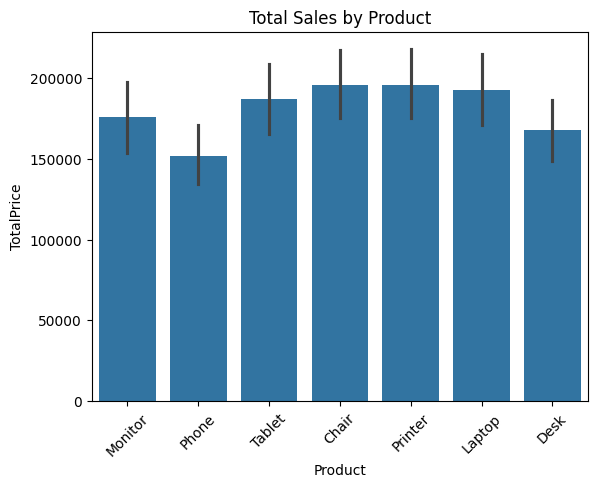

In [139]:
# 1. Sales by product
sns.barplot(data=df, x="Product", y="TotalPrice", estimator="sum")
plt.title("Total Sales by Product")
plt.xticks(rotation=45)
plt.show()

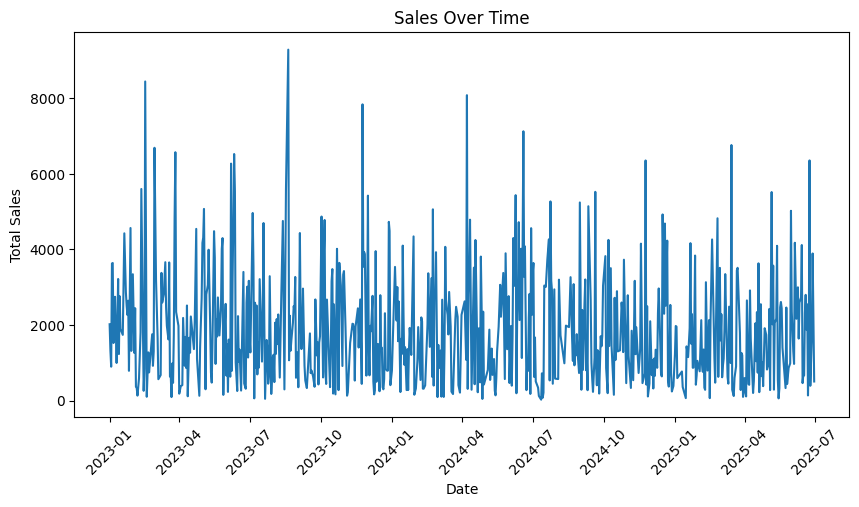

In [140]:
# 2. Sales over time
df["Date"] = pd.to_datetime(df["Date"])

daily_sales = df.groupby("Date")["TotalPrice"].sum()

plt.figure(figsize=(10, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title("Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

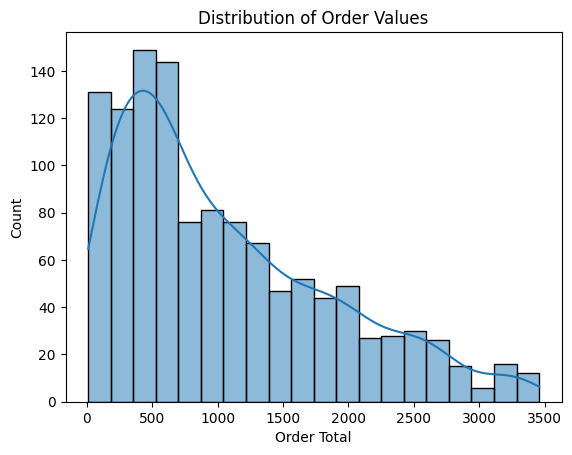

In [141]:
# 3. Distribution of order values
sns.histplot(data=df, x="TotalPrice", bins=20, kde=True)
plt.title("Distribution of Order Values")
plt.xlabel("Order Total")
plt.show()

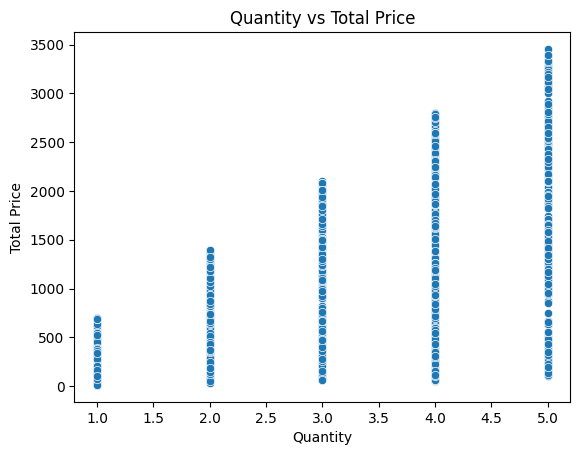

In [142]:
# 4. Quantity vs total price
sns.scatterplot(data=df, x="Quantity", y="TotalPrice")
plt.title("Quantity vs Total Price")
plt.xlabel("Quantity")
plt.ylabel("Total Price")
plt.show()

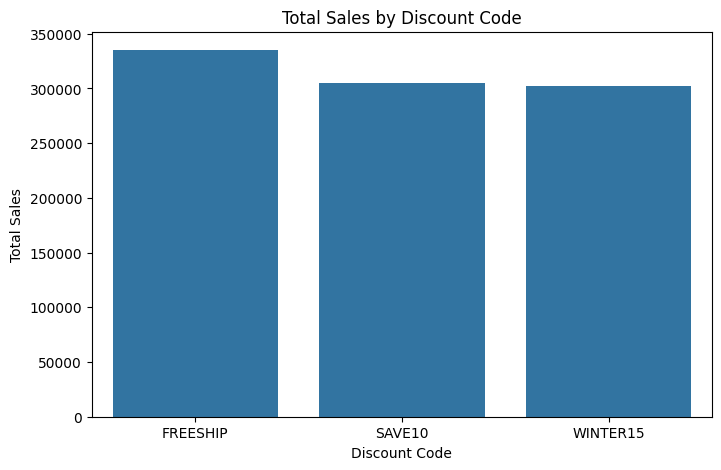

In [144]:
discount_sales = df.groupby("CouponCode")["TotalPrice"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=discount_sales.index, y=discount_sales.values)

plt.title("Total Sales by Discount Code")
plt.xlabel("Discount Code")
plt.ylabel("Total Sales")
plt.show()

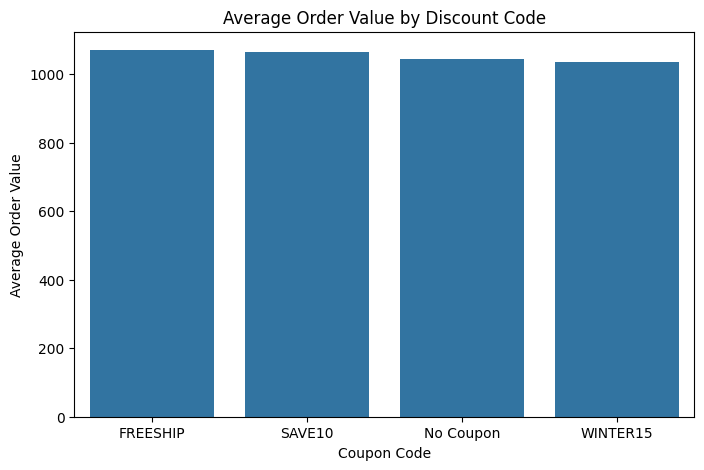

In [154]:
avg_order_discount = (
    df.assign(
        CouponCode=df["CouponCode"].fillna("No Coupon")
    )
    .groupby("CouponCode")["TotalPrice"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=avg_order_discount.index,
    y=avg_order_discount.values
)

plt.title("Average Order Value by Discount Code")
plt.xlabel("Coupon Code")
plt.ylabel("Average Order Value")

plt.show()

Among the coupon codes, FREESHIP was associated with the highest total sales revenue.

Chair had the highest quantity sold and the highest revenue generated, while Phone had the lowest quantity sold and lowest revenue generated. Desk had a higher quantity sold than Tablet and Monitor, but generated less revenue than both, suggesting a lower average revenue per unit for Desk orders.

In [166]:
product_summary = (
    df.groupby("Product")
      .agg(
          TotalQuantity=("Quantity", "sum"),
          TotalRevenue=("TotalPrice", "sum")
      )
)

# Converting each metric into its percentage contribution
product_summary["QuantityPercent"] = (
    product_summary["TotalQuantity"] /
    product_summary["TotalQuantity"].sum() * 100
)

product_summary["RevenuePercent"] = (
    product_summary["TotalRevenue"] /
    product_summary["TotalRevenue"].sum() * 100
)

product_summary

,TotalQuantity,TotalRevenue,QuantityPercent,RevenuePercent
Product,,,,
Chair,562,195620.11,15.898161,15.466951
Desk,508,167459.93,14.370580,13.240431
Laptop,535,192126.56,15.134371,15.190729
Monitor,480,175651.41,13.578501,13.888100
Phone,411,151722.39,11.626591,11.996122
Printer,542,195612.61,15.332390,15.466358
Tablet,497,186568.95,14.059406,14.751309


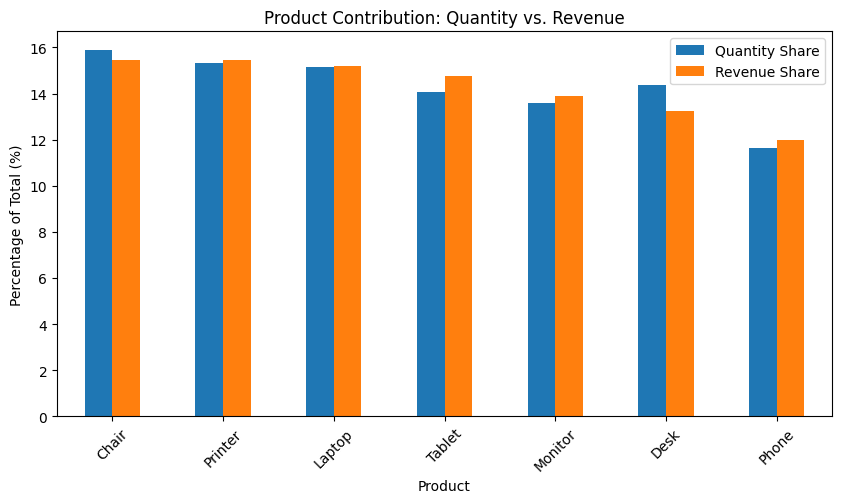

In [170]:
plot_data = product_summary[["QuantityPercent", "RevenuePercent"]].sort_values("RevenuePercent", ascending=False)

plot_data.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Product Contribution: Quantity vs. Revenue")
plt.xlabel("Product")
plt.ylabel("Percentage of Total (%)")
plt.xticks(rotation=45)
plt.legend(["Quantity Share", "Revenue Share"])

plt.show()

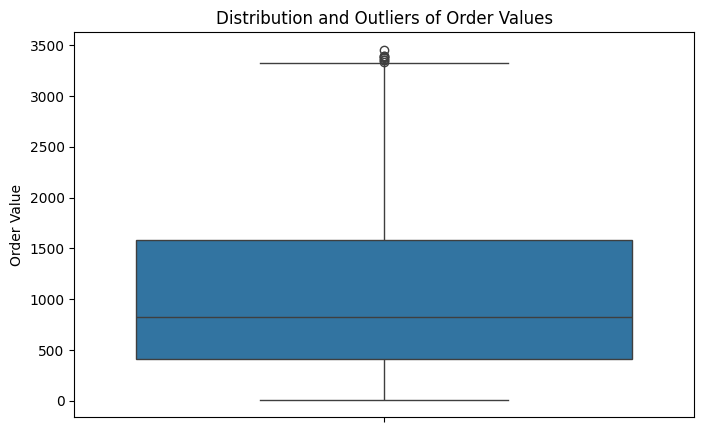

In [171]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df["TotalPrice"])

plt.title("Distribution and Outliers of Order Values")
plt.ylabel("Order Value")

plt.show()

Most orders have relatively lower values, while a smaller number of orders have substantially higher values. The median order value is approximately 823.62, compared with a mean of 1,053.97, suggesting that high-value orders pull the average upward.

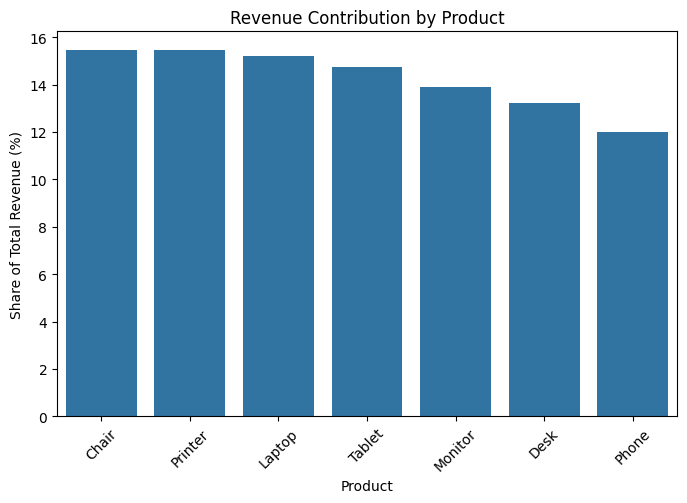

In [172]:
revenue_share = (
    product_summary["RevenuePercent"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=revenue_share.index,
    y=revenue_share.values
)

plt.title("Revenue Contribution by Product")
plt.xlabel("Product")
plt.ylabel("Share of Total Revenue (%)")
plt.xticks(rotation=45)

plt.show()

Chair and Printer each contributed approximately 15.47% of total revenue. However, revenue was distributed relatively evenly across all seven products, with no single product accounting for a dominant share of total revenue.

## 1. Key Findings

* The dataset contains **1,200 orders from 1,189 customers**, with a total of **3,535 units sold** and total revenue of approximately **1.26 million**.
* **Chair** had the highest quantity sold (562 units) and generated the highest total revenue (195,620.11). **Phone** had the lowest quantity sold (411 units) and the lowest total revenue (151,722.39).
* **Chair and Printer each contributed approximately 15.47% of total revenue**, while the remaining products had relatively similar revenue contributions. This indicates that revenue was fairly evenly distributed across the seven products.
* **Desk** had more units sold than Tablet and Monitor but generated less revenue than both, suggesting a lower average revenue per unit.
* The average order value was **1,053.97**, while the median was **823.62**. The higher mean suggests that a smaller number of high-value orders increased the overall average.
* **Credit Card** payments had the highest average order value at approximately **1,127.55**, while **Online** payments had the highest number of orders.
* **309 orders were placed without a coupon code**, while FREESHIP was the most frequently used coupon code. Among the coupon codes, FREESHIP was also associated with the highest total sales revenue.
* The highest-spending customers were not necessarily the customers with the highest order frequency, showing that customer value can differ based on both purchase frequency and order value.
* **Cancelled orders accounted for 20.83% of all orders**, while Shipped and Delivered orders accounted for 19.58% and 19.25%, respectively.

## 2. Overall Conclusion

The analysis provided an overview of sales, products, customers, payment methods, coupons, order values, and order statuses in the sample online-store dataset.

Product performance was relatively balanced, although Chair and Printer contributed the largest shares of revenue. The analysis also showed that order quantity and revenue do not always increase proportionally, as demonstrated by the difference between Desk's quantity sold and its revenue.

Order values were somewhat right-skewed, with a relatively small number of high-value orders increasing the mean above the median. Customer analysis also showed that spending and purchase frequency are not necessarily the same measure of customer value.

Overall, the project demonstrates how data cleaning, exploratory analysis, and visualization can be used together to identify patterns and relationships in transactional data.

## 3. Limitations / Things That Could Be Analyzed Further

* This is a **sample/practice dataset**, so the observed patterns should not be interpreted as representative of a real e-commerce business.
* The dataset covers a limited number of orders and customers, so more data would be needed to draw conclusions about long-term purchasing behavior.
* The analysis mainly focuses on descriptive statistics and visualization; it does not establish **causal relationships**. For example, a higher revenue associated with a particular coupon does not mean that the coupon caused the higher revenue.
* Customer retention could be analyzed further using **repeat-purchase rate, customer lifetime value, and purchase frequency**.
* Product profitability could be investigated if **cost or profit data** were available, since revenue alone does not show which products are most profitable.
* Coupon effectiveness could be studied by comparing **average order value, revenue, and purchase behavior** between coupon and non-coupon orders.
* Sales trends could be examined in greater detail by comparing **monthly or seasonal performance**.
* Order status could be investigated further to understand whether certain products, payment methods, or coupon codes are associated with different order outcomes.
